In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import time

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
import kagglehub
path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

In [4]:

# Download the dataset and list its files

import kagglehub
import os

path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

print("Dataset downloaded successfully!")
print("Dataset path:", path)
print("Files found:", os.listdir(path))


100%|██████████| 211k/211k [00:00<00:00, 57.3MB/s]

Extracting files...
Dataset downloaded successfully!
Dataset path: /root/.cache/kagglehub/datasets/uciml/sms-spam-collection-dataset/versions/1
Files found: ['spam.csv']


In [5]:

# Step 3: Load the dataset

import os
import pandas as pd

csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
print("CSV files found:", csv_files)


CSV files found: ['spam.csv']


In [6]:

# Step 4: Read the CSV file

csv_file = os.path.join(path, csv_files[0])

df = pd.read_csv(csv_file, encoding="latin-1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [7]:

# Step 4: Keep only the required columns and rename them

df = df[['v1', 'v2']].copy()
df.columns = ['label', 'message']

# Check for missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows with missing labels or messages
df = df.dropna(subset=['label', 'message'])

# Remove duplicate messages
df = df.drop_duplicates()

print("\nDataset shape after cleaning:", df.shape)

print("\nFirst 5 cleaned messages:")
display(df.head())


Missing values before cleaning:
label      0
message    0
dtype: int64

Dataset shape after cleaning: (5169, 2)

First 5 cleaned messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Message counts:
label
ham     4516
spam     653
Name: count, dtype: int64

Percentage distribution:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


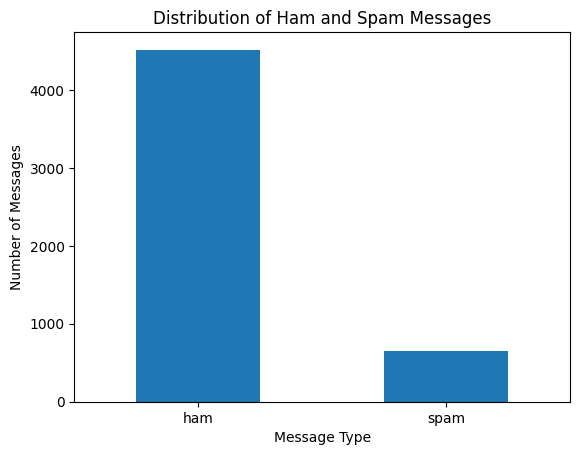

In [8]:

# Step 5: Count ham and spam messages

print("Message counts:")
print(df['label'].value_counts())

print("\nPercentage distribution:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

# Plot the class distribution
df['label'].value_counts().plot(
    kind='bar',
    title='Distribution of Ham and Spam Messages',
    xlabel='Message Type',
    ylabel='Number of Messages',
    rot=0
)

plt.show()


In [9]:

# Step 6: Explore the cleaned dataset

print("Total messages:", len(df))
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nNumber of unique messages:", df['message'].nunique())

print("\nLabel categories:")
print(df['label'].unique())

print("\nSample legitimate message:")
print(df[df['label'] == 'ham']['message'].iloc[0])

print("\nSample spam message:")
print(df[df['label'] == 'spam']['message'].iloc[0])


Total messages: 5169

Column names:
['label', 'message']

Data types:
label      object
message    object
dtype: object

Number of unique messages: 5169

Label categories:
['ham' 'spam']

Sample legitimate message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Sample spam message:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


Message length statistics:
count    5169.000000
mean       78.977945
std        58.236293
min         2.000000
25%        36.000000
50%        60.000000
75%       117.000000
max       910.000000
Name: message_length, dtype: float64

Average message length by label:
label
ham      70.46
spam    137.89
Name: message_length, dtype: float64


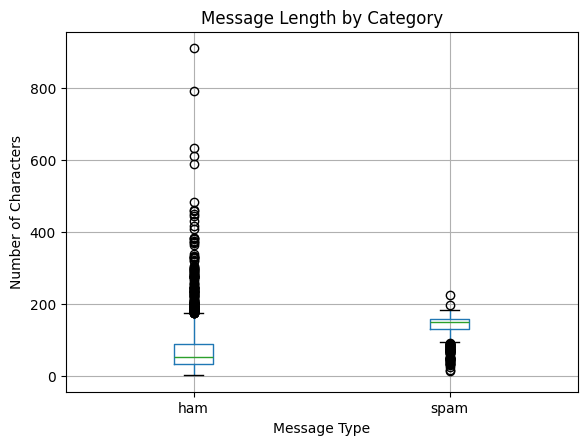

In [10]:

# Step 7: Analyze message lengths

df['message_length'] = df['message'].str.len()

print("Message length statistics:")
print(df['message_length'].describe())

# Compare message lengths by category
print("\nAverage message length by label:")
print(df.groupby('label')['message_length'].mean().round(2))

# Visualize message lengths
df.boxplot(column='message_length', by='label')
plt.title('Message Length by Category')
plt.suptitle('')
plt.xlabel('Message Type')
plt.ylabel('Number of Characters')
plt.show()


In [11]:

# Step 8: Separate input text and target labels

X = df['message'].copy()
y = df['label'].copy()

print("Input text shape:", X.shape)
print("Target labels shape:", y.shape)

print("\nInput example:")
print(X.iloc[0])

print("\nTarget label:")
print(y.iloc[0])

print("\nLabel counts:")
print(y.value_counts())


Input text shape: (5169,)
Target labels shape: (5169,)

Input example:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Target label:
ham

Label counts:
label
ham     4516
spam     653
Name: count, dtype: int64


In [12]:

# Step 9: Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())


Training messages: 4135
Testing messages: 1034

Training label distribution:
label
ham     3613
spam     522
Name: count, dtype: int64

Testing label distribution:
label
ham     903
spam    131
Name: count, dtype: int64


In [13]:

# Step 10: TF-IDF feature extraction

tfidf = TfidfVectorizer(stop_words='english')

# Learn vocabulary only from training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion successful!")
print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of unique features:", len(tfidf.get_feature_names_out()))


TF-IDF conversion successful!
Training feature shape: (4135, 7329)
Testing feature shape: (1034, 7329)
Number of unique features: 7329


In [14]:

# Step 11: Train the four machine learning models

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel='linear', random_state=42),
    "Naive Bayes": MultinomialNB()
}

training_times = {}

for name, model in models.items():
    start_time = time.time()

    model.fit(X_train_tfidf, y_train)

    end_time = time.time()
    training_times[name] = end_time - start_time

    print(f"{name} trained successfully!")
    print(f"Training time: {training_times[name]:.4f} seconds")
    print("-" * 40)


Decision Tree trained successfully!
Training time: 0.6844 seconds
----------------------------------------
KNN trained successfully!
Training time: 0.0072 seconds
----------------------------------------
SVM trained successfully!
Training time: 1.3553 seconds
----------------------------------------
Naive Bayes trained successfully!
Training time: 0.0328 seconds
----------------------------------------


In [15]:

# Step 12: Evaluate all four classifiers

results = []

for name, model in models.items():
    start_time = time.time()

    y_pred = model.predict(X_test_tfidf)

    prediction_time = time.time() - start_time

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Training Time (s)": training_times[name],
        "Prediction Time (s)": prediction_time
    })

results_df = pd.DataFrame(results)

print("MODEL COMPARISON RESULTS")
display(results_df.round(4))


MODEL COMPARISON RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s),Prediction Time (s)
0,Decision Tree,0.9565,0.8359,0.8168,0.8263,0.6844,0.0026
1,KNN,0.9033,1.0000,0.2366,0.3827,0.0072,0.2233
2,SVM,0.9797,0.9911,0.8473,0.9136,1.3553,0.1690
3,Naive Bayes,0.9662,0.9898,0.7405,0.8472,0.0328,0.0007


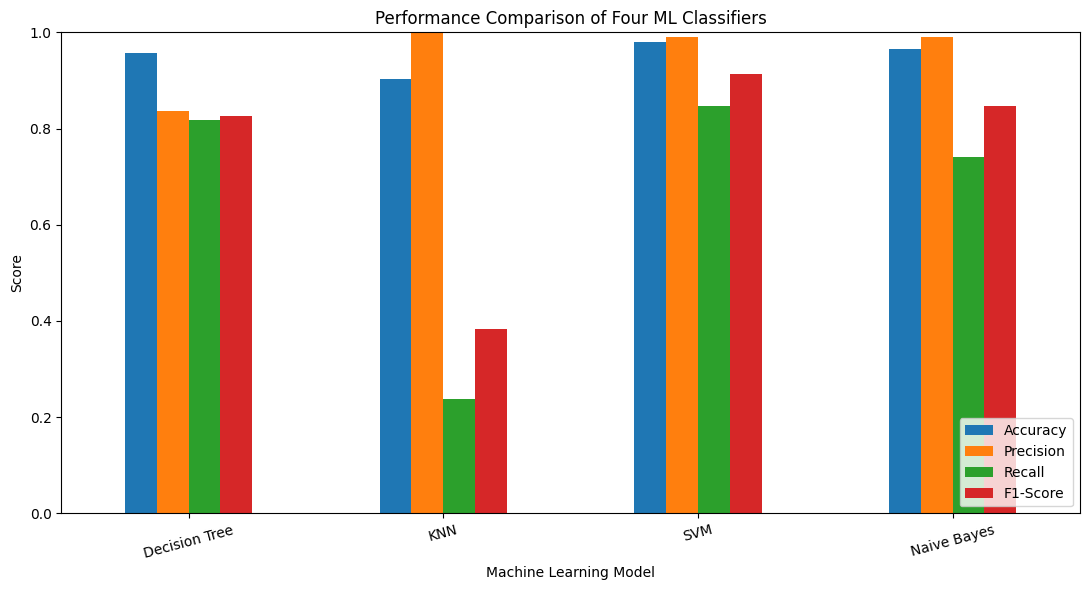

In [16]:

# Step 13: Visual comparison of evaluation metrics

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=15
)

plt.title("Performance Comparison of Four ML Classifiers")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


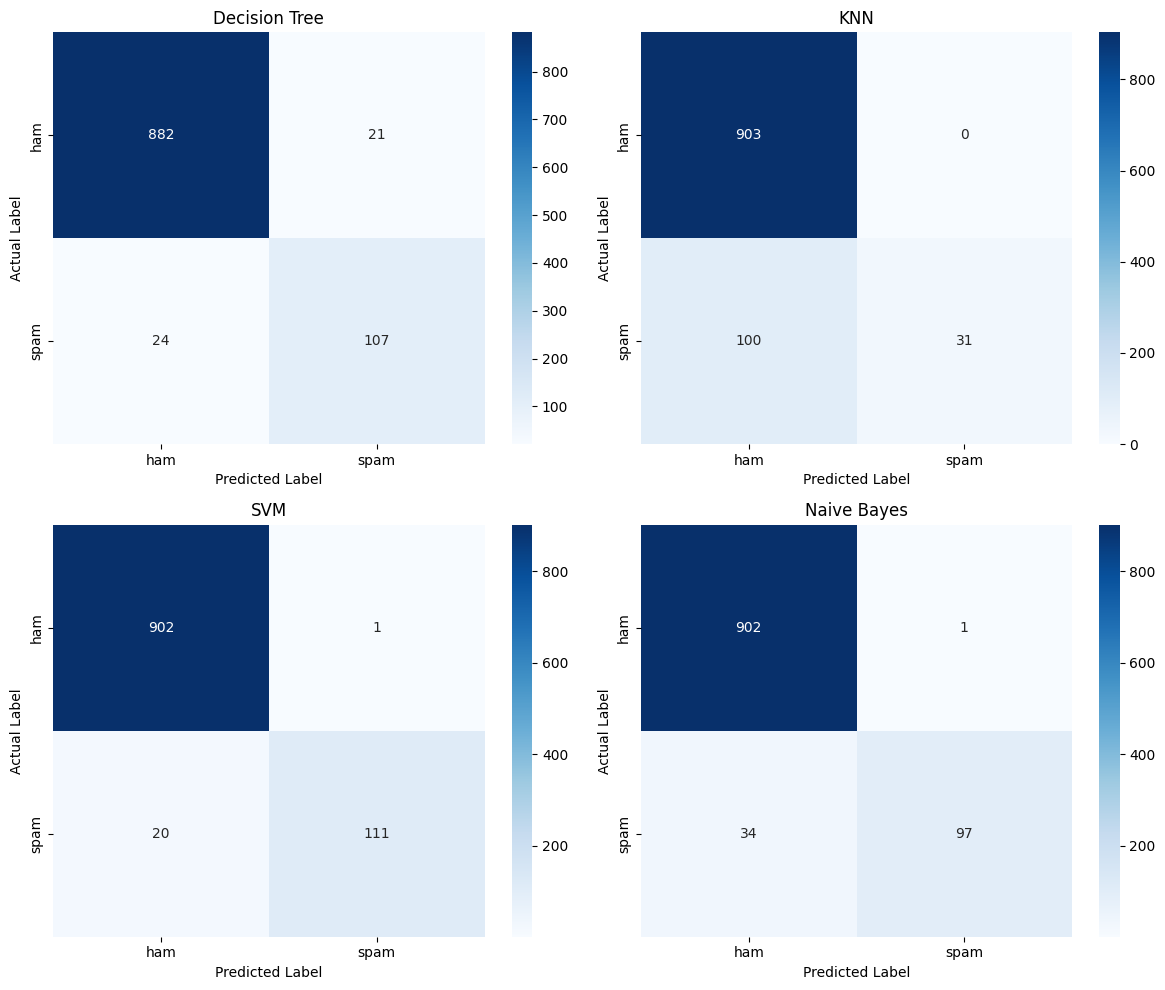

In [17]:

# Step 15: Confusion matrices for all four models

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


In [18]:
# What-if experiment: Change the SVM parameter C

svm_experiment_results = []

for c_value in [0.1, 10]:
    experiment_model = SVC(
        kernel='linear',
        C=c_value,
        random_state=42
    )

    start_time = time.time()
    experiment_model.fit(X_train_tfidf, y_train)
    training_time = time.time() - start_time

    y_pred = experiment_model.predict(X_test_tfidf)

    svm_experiment_results.append({
        "SVM C Value": c_value,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Training Time (s)": training_time
    })

svm_experiment_df = pd.DataFrame(svm_experiment_results)

print("SVM WHAT-IF EXPERIMENT RESULTS")
display(svm_experiment_df.round(4))

SVM WHAT-IF EXPERIMENT RESULTS


,SVM C Value,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,0.1,0.9275,1.0000,0.4275,0.5989,0.8185
1,10.0,0.9826,0.9829,0.8779,0.9274,0.4354


In [19]:
# Final classification report for the best SVM model

best_svm = SVC(
    kernel='linear',
    C=10,
    random_state=42
)

best_svm.fit(X_train_tfidf, y_train)

y_pred_best = best_svm.predict(X_test_tfidf)

print("FINAL CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_best,
    labels=["ham", "spam"],
    zero_division=0
))

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.98      0.88      0.93       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



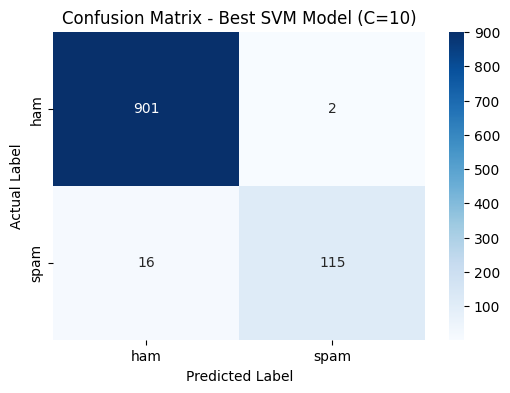

Confusion Matrix:
[[901   2]
 [ 16 115]]


In [20]:
# Confusion matrix for the best SVM model

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=["ham", "spam"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.title("Confusion Matrix - Best SVM Model (C=10)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion Matrix:")
print(cm)

In [21]:
# Save comparison results to a CSV file

results_df.to_csv("model_comparison_results.csv", index=False)

print("Model comparison results saved successfully!")
print("File name: model_comparison_results.csv")

display(results_df.round(4))

Model comparison results saved successfully!
File name: model_comparison_results.csv


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s),Prediction Time (s)
0,Decision Tree,0.9565,0.8359,0.8168,0.8263,0.6844,0.0026
1,KNN,0.9033,1.0000,0.2366,0.3827,0.0072,0.2233
2,SVM,0.9797,0.9911,0.8473,0.9136,1.3553,0.1690
3,Naive Bayes,0.9662,0.9898,0.7405,0.8472,0.0328,0.0007


In [22]:
# Save SVM what-if experiment results

svm_experiment_df.to_csv(
    "svm_what_if_results.csv",
    index=False
)

print("What-if experiment results saved successfully!")
print("File name: svm_what_if_results.csv")

display(svm_experiment_df.round(4))

What-if experiment results saved successfully!
File name: svm_what_if_results.csv


,SVM C Value,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,0.1,0.9275,1.0000,0.4275,0.5989,0.8185
1,10.0,0.9826,0.9829,0.8779,0.9274,0.4354


In [23]:
# Final Project Summary

best_model_row = results_df.loc[results_df["F1-Score"].idxmax()]

print("=" * 50)
print("SMS SPAM CLASSIFICATION - PROJECT SUMMARY")
print("=" * 50)

print("\n1. Dataset")
print("Dataset: SMS Spam Collection")
print(f"Total messages after cleaning: {len(df)}")
print(f"Training messages: {len(X_train)}")
print(f"Testing messages: {len(X_test)}")

print("\n2. Algorithms Used")
for model_name in models.keys():
    print("-", model_name)

print("\n3. Best Model Among Original Four")
print("Model:", best_model_row["Model"])
print(f"Accuracy: {best_model_row['Accuracy'] * 100:.2f}%")
print(f"Precision: {best_model_row['Precision'] * 100:.2f}%")
print(f"Recall: {best_model_row['Recall'] * 100:.2f}%")
print(f"F1-Score: {best_model_row['F1-Score'] * 100:.2f}%")

print("\n4. What-if Experiment")
print("Parameter: SVM C")
print("Baseline C=1: Accuracy 97.97%, F1-score 91.36%")
print("C=0.1: Accuracy 92.75%, F1-score 59.89%")
print("C=10: Accuracy 98.26%, F1-score 92.74%")

print("\n5. Saved Results")
print("- model_comparison_results.csv")
print("- svm_what_if_results.csv")

print("\nProject summary generated successfully!")

SMS SPAM CLASSIFICATION - PROJECT SUMMARY

1. Dataset
Dataset: SMS Spam Collection
Total messages after cleaning: 5169
Training messages: 4135
Testing messages: 1034

2. Algorithms Used
- Decision Tree
- KNN
- SVM
- Naive Bayes

3. Best Model Among Original Four
Model: SVM
Accuracy: 97.97%
Precision: 99.11%
Recall: 84.73%
F1-Score: 91.36%

4. What-if Experiment
Parameter: SVM C
Baseline C=1: Accuracy 97.97%, F1-score 91.36%
C=0.1: Accuracy 92.75%, F1-score 59.89%
C=10: Accuracy 98.26%, F1-score 92.74%

5. Saved Results
- model_comparison_results.csv
- svm_what_if_results.csv

Project summary generated successfully!


In [24]:
summary = f"""
SMS SPAM CLASSIFICATION USING MACHINE LEARNING

1. OBJECTIVE
Classify SMS messages as ham (normal) or spam using machine learning.

2. DATASET
Dataset: SMS Spam Collection
Messages after cleaning: {len(df)}
Training messages: {len(X_train)}
Testing messages: {len(X_test)}

3. TEXT PREPROCESSING
- Removed unnecessary columns.
- Removed duplicate messages and missing entries.
- Converted text into numerical features using TF-IDF.
- Used an 80:20 training/testing split.

4. ALGORITHMS
- Decision Tree
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)
- Naive Bayes

5. BEST ORIGINAL MODEL
SVM with C=1
Accuracy: 97.97%
Precision: 99.11%
Recall: 84.73%
F1-score: 91.36%

6. WHAT-IF EXPERIMENT
SVM parameter C=0.1:
Accuracy: 92.75%
F1-score: 59.89%

SVM parameter C=10:
Accuracy: 98.26%
F1-score: 92.74%

The SVM with C=10 performed best among the three tested C values.

7. CONFUSION MATRIX FOR SVM WITH C=10
True negatives (ham correctly classified): 901
False positives (ham classified as spam): 2
False negatives (spam classified as ham): 16
True positives (spam correctly classified): 115

8. CONCLUSION
The SVM classifier achieved the best performance among the four
original classifiers, with 97.97% accuracy. The what-if experiment
improved the SVM accuracy to 98.26% and F1-score to 92.74% when
C was changed from 1 to 10.
"""

with open("project_summary.txt", "w", encoding="utf-8") as file:
    file.write(summary)

print("Final summary saved as project_summary.txt")

Final summary saved as project_summary.txt
